# Manual Day — Statistics and Monte Carlo

Closed-agent, ~60 min. Complete every `# FILL IN` cell, then run the check.

**Five problems. Work in order, as many as time permits.** The last one is a challenge.

If you can draw samples from a distribution, you can estimate any average over it,
and the same samples tell you roughly how far off that estimate is. Problems 1 to 3
produce samples, and Problems 4 and 5 turn them into estimates with error bars. The
mini-lecture covers the statistics and the Metropolis algorithm, and each problem
starts with the background it needs.

## Mini-lecture: statistics and Metropolis

### A little statistics

A random variable $x$ is described by a **probability density** $p(x)$, with
$p \ge 0$ and $\int p(x)\,dx = 1$. The chance of landing in $[x, x+dx]$ is
$p(x)\,dx$. The **expectation value** of a function $f$ is its average weighted by
$p$:

$$\langle f \rangle = \int f(x)\,p(x)\,dx.$$

The **mean** is $\mu = \langle x\rangle$, and the **variance** is the mean squared
distance from it,

$$\sigma^2 = \big\langle (x-\mu)^2 \big\rangle = \langle x^2\rangle - \langle x\rangle^2 .$$

Its square root $\sigma$, the standard deviation, measures the width.

The uniform density on $[0,1)$ is $p = 1$, so $\langle x\rangle = 1/2$ and
$\sigma^2 = 1/3 - 1/4 = 1/12$. The Gaussian

$$p(x) = \frac{1}{\sqrt{2\pi\sigma^2}}\,e^{-x^2/2\sigma^2}$$

has mean zero and variance $\sigma^2$. Its odd moments vanish by symmetry, and the
even ones are

$$\langle x^{2n}\rangle = (2n-1)!!\,\sigma^{2n}, \qquad\text{so } 1,\ 3,\ 15,\ 105,\ \dots \text{ at } \sigma = 1 .$$

The double factorial $(2n-1)!! = (2n-1)(2n-3)\cdots 1$ counts the ways to join $2n$
points in pairs. That counting is Wick's theorem, the combinatorics behind Feynman
diagrams.

On a computer you usually can't do the integral against $p$. You have samples
$x_1, \dots, x_N$ drawn independently from $p$ instead, and the sample mean stands
in for the expectation value:

$$\langle f\rangle = \int f(x)\,p(x)\,dx \;\approx\; \bar f = \frac1N \sum_{i=1}^{N} f(x_i) .$$

By the law of large numbers, $\bar f \to \langle f\rangle$ as $N$ grows. This is
Monte Carlo estimation.

The average $\bar f$ is itself random, since a fresh set of samples gives a slightly
different number. To find its variance, write $f_i = f(x_i)$ and
$\mu = \langle f\rangle$. Then $\bar f - \mu = \frac1N \sum_i (f_i - \mu)$, and
squaring turns the sum into a double sum:

$$\mathrm{Var}(\bar f) = \big\langle (\bar f - \mu)^2 \big\rangle
= \frac{1}{N^2}\sum_{i=1}^{N}\sum_{j=1}^{N} \big\langle (f_i-\mu)(f_j-\mu)\big\rangle .$$

The terms with $i = j$ are the variances $\mathrm{Var}(f_i)$. The terms with
$i \ne j$ are covariances, and for independent samples each one factorizes and
vanishes,
$\big\langle (f_i-\mu)(f_j-\mu)\big\rangle = \langle f_i-\mu\rangle\,\langle f_j-\mu\rangle = 0$.
Only the $N$ diagonal terms survive, and each one equals
$\sigma_f^2 = \langle f^2\rangle - \langle f\rangle^2$, so

$$\mathrm{Var}(\bar f) = \frac{1}{N^2}\sum_{i=1}^{N} \mathrm{Var}(f_i) = \frac{N\sigma_f^2}{N^2} = \frac{\sigma_f^2}{N},$$

and the **error bar** on the estimate is

$$\Delta = \frac{\sigma_f}{\sqrt N} .$$

By the central limit theorem, repeated estimates scatter as a Gaussian of that width.

Keep the two widths separate. $\sigma_f$ is the spread of the individual values
$f(x_i)$. It's set by $f$ and $p$, and more samples don't make it smaller.
$\sigma_f/\sqrt N$ is the spread of the average, and it falls slowly: one more digit
costs a hundred times more samples. Since you estimate $\sigma_f$ from the same
samples, one run gives you both the number and its error bar.

### Metropolis: sampling from ratios

The direct way to get samples is to transform uniform random numbers, which you'll
do in Problem 2. That works when you can write down the cumulative distribution and
invert it, which means knowing the normalization. Often you know $p$ only up to a
constant. The Boltzmann weight $e^{-E/kT}$ is easy to write down, and its
normalization, the partition function, is the hard part. The Metropolis algorithm
avoids the normalization with a random walk whose positions, after enough steps, are
distributed as $p$. From the current position $x$:

1. Propose $x' = x + \delta\,(2u - 1)$, a uniform step in $[-\delta, \delta]$.
2. Accept it with probability $A = \min\big(1,\ p(x')/p(x)\big)$. You always accept
   an uphill move, and a downhill one only sometimes.
3. If you reject, stay at $x$ and record $x$ again.

To see why this works, let $w(x\to x')$ be the **transition probability**: the
probability (a density, since $x$ is continuous) that one step of the walk takes the
walker from $x$ to a different point $x'$. It's the chance of proposing $x'$ times
the chance of accepting it,

$$w(x\to x') = q(x'\,|\,x)\,A(x\to x'),$$

where $q(x'\,|\,x) = 1/(2\delta)$ for $|x'-x| \le \delta$ is the uniform proposal
density from step 1, and $A(x\to x')$ is the acceptance probability from step 2.
The walk's distribution stops changing once, at every $x$, the probability flowing
in equals the probability flowing out. A simpler condition that guarantees this is
**detailed balance**, where the flow between each pair of points balances on its
own:

$$p(x)\,w(x\to x') = p(x')\,w(x'\to x) .$$

The proposal is symmetric, $q(x'\,|\,x) = q(x\,|\,x')$, so it cancels from both
sides and leaves $p(x)\,A(x\to x') = p(x')\,A(x'\to x)$. The $\min$ rule satisfies
that. Take $p(x') < p(x)$: the left side is $p(x)\cdot p(x')/p(x) = p(x')$, and the
right side is $p(x')\cdot 1$. Only the ratio
$p(x')/p(x)$ appears, so the normalization cancels. That's what lets us simulate the
Ising model next week.

The step size $\delta$ controls the acceptance rate. Make it too large and almost
every proposal is rejected; make it too small and the walker barely moves. A common
rule of thumb is to accept about a third to a half of proposals. Start the walk
where $p$ is largest, and even then throw away an initial **burn-in** before you
measure anything. Successive positions are also correlated, so they aren't the
independent samples the error bar above assumes (the $i \ne j$ covariances no longer
vanish), which is why codes often record
only every tenth step. Problem 3 builds the sampler.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Problem 1 — a uniform generator from scratch

A computer is deterministic, so the random numbers it produces are
**pseudo-random**: a fixed sequence that passes enough statistical tests to stand in
for random numbers. The oldest recipe is the **linear congruential generator**, here
in its multiplicative form,

$$r_{n+1} = (a\,r_n) \bmod m, \qquad u_n = r_n/m ,$$

started from a **seed** $r_0$. Every $u_n$ lands in $[0,1)$, and with good choices of
$a$ and $m$ the values look uniform. There are only $m$ possible values, so the
sequence eventually repeats, and each number is fixed by the one before it.

A bad choice can still pass the one-dimensional tests. RANDU, IBM's generator from
the 1960s, used $a = 65539$ and $m = 2^{31}$. Its histogram is flat and its mean and
variance are right, but every triple $(u_n, u_{n+1}, u_{n+2})$ lies on one of only 15
planes in the unit cube. (The algebra is $a^2 \equiv 6a - 9 \pmod{2^{31}}$, since
$a = 2^{16}+3$.) A 3D simulation driven by RANDU visits only those 15 slices of the
cube, so test a generator in the dimension you plan to use it in.

Code the generator as a function `lcg(a, m, seed, N)` that returns $u_1, \dots, u_N$
as a NumPy array. The check runs it with three choices of $(a, m)$:

* `large`: $a = 52361276312121$, $m = 6537169170218971$, an arbitrary big pair
* `randu`: $a = 65539$, $m = 2^{31}$, the real RANDU
* `toy`: $a = 112$, $m = 2555$

Keep $r$ a plain Python integer inside the loop, since Python integers can't
overflow. Here $a\,r$ reaches $10^{29}$. A NumPy `int64` wraps around past
$2^{63} \approx 9\times10^{18}$ with at most a warning, and a float keeps only about
16 significant digits. Either one gives you a sequence that looks uniform and differs
from the recurrence you wrote down.

After today we'll use `np.random.default_rng()`, a much better generator. It's still
an algorithm, and the seed is what makes a run reproducible.

**Known answers.** The large generator and RANDU both pass the one-dimensional tests,
with mean $1/2$ and variance $1/12 = 0.0833$. In three dimensions they differ. For
RANDU, $9u_n - 6u_{n+1} + u_{n+2}$ is an exact integer for every $n$ and takes only
the 15 values $-5, \dots, 9$, so every triple sits on one of 15 planes. The large
generator shows no such pattern. The toy repeats after 72 numbers, the longest cycle
any multiplier can give with $m = 2555$.

In [2]:
# GIVEN — the three generators and the seed (do not change)
N    = 100_000
seed = 1
large = dict(a=52361276312121, m=6537169170218971)   # big and arbitrary
randu = dict(a=65539,          m=2**31)              # IBM, 1960s
toy   = dict(a=112,            m=2555)               # small enough to see through

In [3]:
# FILL IN: the generator r -> (a*r) % m, returning u_n = r_n/m for n = 1..N.
#          Keep r a Python int; only the scaled u goes into the NumPy array.
def lcg(a, m, seed, N):
    u = np.zeros(N)
    r = seed
    for i in range(N):
        r = (a*r) % m           # one step of the recurrence
        u[i] = r/m        # scale into [0, 1)
    return u

large  mean = 0.5002  (1/2)   variance = 0.08331  (1/12 = 0.08333)
RANDU  mean = 0.5019  (1/2)   variance = 0.08334  (1/12 = 0.08333)

RANDU: 9u_n - 6u_(n+1) + u_(n+2) is an integer for 100% of triples, taking 15 values
large: an integer for 0.01% of triples

toy: 72 distinct values, and u_73 = u_1: True
OK


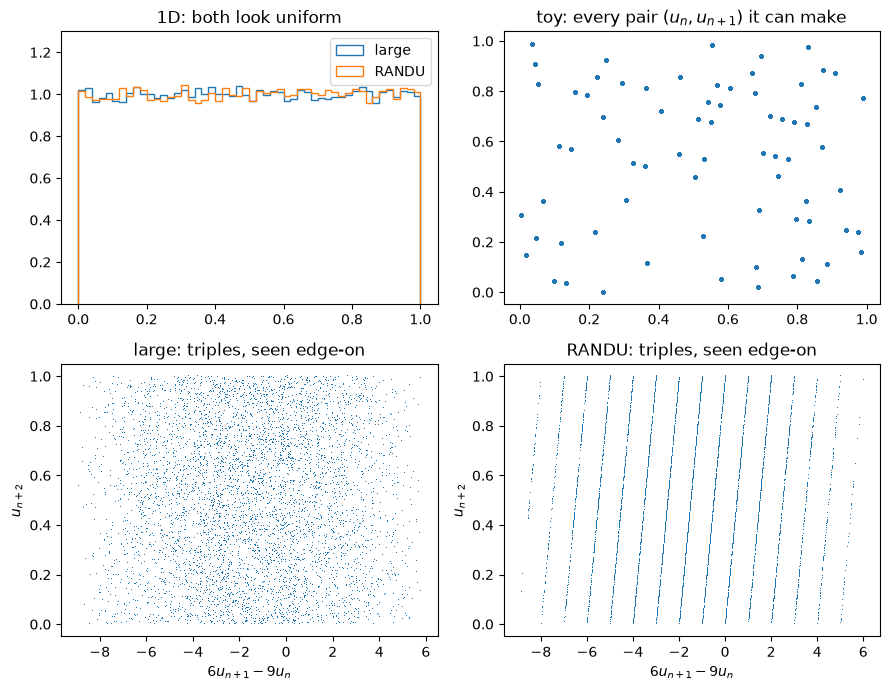

In [4]:
# CHECK — do not edit
u_large = lcg(**large, seed=seed, N=N)
u_randu = lcg(**randu, seed=seed, N=N)
u_toy   = lcg(**toy,   seed=seed, N=N)

for name, u in [("large", u_large), ("RANDU", u_randu)]:
    print("%-6s mean = %.4f  (1/2)   variance = %.5f  (1/12 = %.5f)" % (name, u.mean(), u.var(), 1/12))
    assert abs(u.mean() - 0.5) < 5e-3 and abs(u.var() - 1/12) < 2e-3, name + " fails the 1D test"

def triples(u):
    return 9*u[:-2] - 6*u[1:-1] + u[2:]

k_r, k_l = triples(u_randu), triples(u_large)
print("\nRANDU: 9u_n - 6u_(n+1) + u_(n+2) is an integer for %.0f%% of triples, taking %d values"
      % (100*np.mean(k_r == np.round(k_r)), np.unique(k_r).size))
print("large: an integer for %.2f%% of triples" % (100*np.mean(np.isclose(k_l, np.round(k_l)))))
assert np.all(k_r == np.round(k_r)) and np.unique(k_r).size == 15, "RANDU should give exactly 15 planes"
assert np.mean(np.isclose(k_l, np.round(k_l))) < 0.01, "the large generator should not sit on planes"

period = np.unique(u_toy).size
print("\ntoy: %d distinct values, and u_%d = u_1: %s" % (period, period + 1, u_toy[period] == u_toy[0]))
assert period == 72 and u_toy[72] == u_toy[0], "the toy generator should repeat after 72 numbers"
print("OK")

n = 5000
fig, ax = plt.subplots(2, 2, figsize=(9, 7))
ax[0, 0].hist(u_large, bins=50, density=True, histtype="step", label="large")
ax[0, 0].hist(u_randu, bins=50, density=True, histtype="step", label="RANDU")
ax[0, 0].set_ylim(0, 1.3); ax[0, 0].legend(); ax[0, 0].set_title("1D: both look uniform")
ax[0, 1].plot(u_toy[:-1], u_toy[1:], ".", ms=4)
ax[0, 1].set_title("toy: every pair $(u_n, u_{n+1})$ it can make")
for a_, u, t in [(ax[1, 0], u_large, "large"), (ax[1, 1], u_randu, "RANDU")]:
    a_.plot(6*u[1:n+1] - 9*u[:n], u[2:n+2], ",")
    a_.set_xlabel(r"$6u_{n+1} - 9u_n$"); a_.set_ylabel(r"$u_{n+2}$")
    a_.set_title(t + ": triples, seen edge-on")
plt.tight_layout();

## Problem 2 — reshaping uniforms: inverse transform and Box-Muller

To sample anything other than a uniform distribution, you transform uniform numbers.
If $u$ is uniform on $[0,1)$ and $y = y(u)$, probability is conserved under the
change of variables:

$$p(y)\,dy = p(u)\,du \quad\Longrightarrow\quad p(y) = \frac{du}{dy} .$$

To produce a target $p(y)$ you therefore need $du/dy = p(y)$, which integrates to
$u = F(y) = \int_{-\infty}^{y} p(y')\,dy'$, the **cumulative distribution function**.
Inverting it gives the **inverse transform**, $y = F^{-1}(u)$. For the exponential
$p(y) = \lambda e^{-\lambda y}$, the distribution of radioactive decay times,
$F(y) = 1 - e^{-\lambda y}$, so

$$y = -\frac{\ln(1-u)}{\lambda} .$$

The Gaussian has no elementary $F^{-1}$, but a pair of independent Gaussians is
radially symmetric. In polar coordinates,
$e^{-(x^2+y^2)/2}\,dx\,dy = e^{-r^2/2}\,r\,dr\,d\theta$, so the angle is uniform and
$r^2/2$ is exponential, which you can sample with the formula above. Together they
give **Box-Muller**,

$$z_0 = \sqrt{-2\ln u_1}\,\cos 2\pi u_2, \qquad z_1 = \sqrt{-2\ln u_1}\,\sin 2\pi u_2 ,$$

two independent standard normals from two independent uniforms.

Code both transforms, one line each, and concatenate $z_0$ and $z_1$ into one sample
`z`. The uniforms come from NumPy rather than your generator from Problem 1, so a bug
there can't affect this problem.

**Known answers.** The exponential with $\lambda = 0.1$ has mean $1/\lambda = 10$ and
variance $1/\lambda^2 = 100$. The normals have mean 0, variance 1, and fourth moment
$\langle z^4\rangle = 3$, the $(2n-1)!!$ from the mini-lecture. Both histograms
should lie on top of their densities.

*Aside.* When you can evaluate $p$ but can't invert $F$, you can use **rejection
sampling**, due to von Neumann in 1951. Throw points uniformly into a box around the
curve and keep the $x$ of every point that falls under $p(x)$. The kept values are
distributed as $p$. The fraction you keep is the ratio of the two areas, so a
tighter box wastes fewer points. The $\pi$ estimate on the numerical-integration day
was a rejection sampler: it kept the points inside the circle, and the kept fraction
was $\pi/4$.

In [5]:
# GIVEN — uniforms on [0, 1) and the decay rate (do not change)
rng = np.random.default_rng(0)
N   = 100_000
u, u1, u2 = rng.random(N), rng.random(N), rng.random(N)
lam = 0.1

In [7]:
# FILL IN: the inverse transform for the exponential, then Box-Muller for the Gaussian.
y  = -np.log(1-u)/lam                    # exponential with rate lam, from u
z0 = np.sqrt(-2*np.log(u1))*np.cos(2*np.pi*u2)                    # Box-Muller, cosine branch, from u1 and u2
z1 = np.sqrt(-2*np.log(u1))*np.sin(2*np.pi*u2)                      # Box-Muller, sine branch
z  = np.concatenate([z0, z1])

exponential: mean = 9.983 (expect 10)   variance = 100.12 (expect 100)
normal:      mean = -0.0013 (expect 0)    variance = 1.0022 (expect 1)   <z^4> = 3.019 (expect 3)
OK


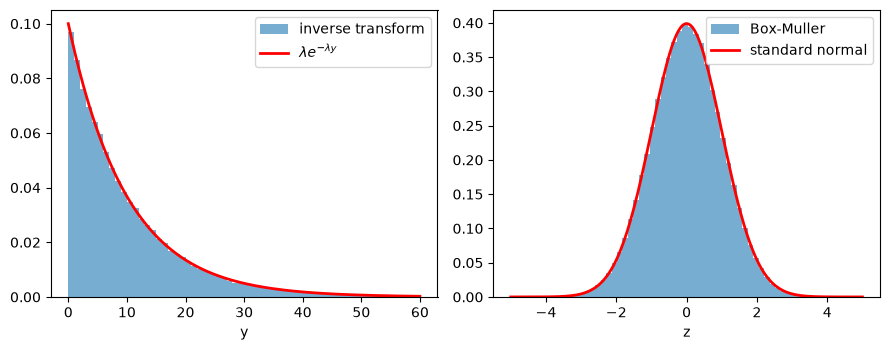

In [9]:
# CHECK — do not edit
print("exponential: mean = %.3f (expect %g)   variance = %.2f (expect %g)" % (y.mean(), 1/lam, y.var(), 1/lam**2))
print("normal:      mean = %.4f (expect 0)    variance = %.4f (expect 1)   <z^4> = %.3f (expect 3)"
      % (z.mean(), z.var(), (z**4).mean()))
assert abs(y.mean() - 1/lam) < 0.15 and abs(y.var() - 1/lam**2) < 5, "exponential has the wrong moments"
assert abs(z.mean()) < 0.01 and abs(z.var() - 1) < 0.015, "normal has the wrong mean or variance"
assert abs((z**4).mean() - 3) < 0.1, "normal has the wrong fourth moment"
print("OK")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.6))
yy = np.linspace(0, 60, 200)
a1.hist(y, bins=np.arange(0, 60, 1), density=True, alpha=0.6, label="inverse transform")
a1.plot(yy, lam*np.exp(-lam*yy), "r-", lw=2, label=r"$\lambda e^{-\lambda y}$")
a1.set_xlabel("y"); a1.legend()
grid = np.linspace(-5, 5, 200)
a2.hist(z, bins=60, density=True, alpha=0.6, label="Box-Muller")
a2.plot(grid, np.exp(-grid**2/2)/np.sqrt(2*np.pi), "r-", lw=2, label="standard normal")
a2.set_xlabel("z"); a2.legend()
plt.tight_layout();

## Problem 3 — Metropolis sampler for a 1D Gaussian

Build a random walk whose stationary distribution is the Gaussian `P(x)` below. `P`
isn't normalized, and it doesn't need to be, since only ratios enter.

From the current `x`, propose `x_try = x + (2*np.random.rand() - 1)*delta`, form the
ratio `A = P(x_try)/P(x)`, and accept (`x = x_try`) when `np.random.rand() < A`. That
comparison accepts with probability $\min(1, A)$, because a uniform number is always
below an $A \ge 1$. Count the acceptances, and record `x` at **every** step,
including the steps where you rejected and stayed put. Leaving those out is the
classic Metropolis bug, and it gives you the wrong distribution.

**Known answers.** After burn-in the samples have mean $\approx 0$ and variance
$\approx \sigma^2 = 1$, and at $\delta = 2.5$ about 56% of proposals are accepted.
The histogram should match the normalized Gaussian. The check also runs your sampler
at $\delta = 0.1$ and $\delta = 25$. Both still sample the right distribution in the
long run, but slowly: the first accepts 98% of its steps and barely moves, and the
second accepts 6% and stays put most of the time.

In [11]:
# GIVEN — target distribution and parameters (do not change)
sigma = 1.0                       # width of the target Gaussian
def P(x):
    # unnormalized target density, P(x) ~ exp(-x^2 / (2 sigma^2))
    return np.exp(-x**2 / (2 * sigma**2))

delta   = 2.5        # proposal step size
N       = 100_000    # number of Metropolis steps
x0      = 0.0        # start where P is largest
burn_in = 1000       # steps to discard before measuring anything

In [16]:
# FILL IN: the Metropolis walk. Propose x_try, accept with probability min(1, P(x_try)/P(x)),
#          and record x at every step. Return the samples and the acceptance fraction.
#          The uniform step is a symmetric proposal, q(x_try|x) = q(x|x_try), so q cancels
#          in detailed balance and the acceptance needs only the ratio P(x_try)/P(x).
def metropolis(delta, N=N, x0=x0):
    samples  = np.zeros(N)
    x        = x0
    n_accept = 0
    for i in range(N):
        x_try = x+delta*(2*np.random.rand()-1)           # uniform step in [-delta, delta]
        A = P(x_try)/P(x)               # acceptance ratio
        if np.random.rand() < A:               # accept?
            x = x_try
            n_accept += 1
        samples[i] = x                   # record x, whether or not you moved
    return samples, n_accept / N

delta = 2.5:  mean = 0.008 (expect 0)   variance = 0.994 (expect 1.0)   accepted 56%
delta = 0.1  accepted 98%
delta = 25   accepted 6%
OK


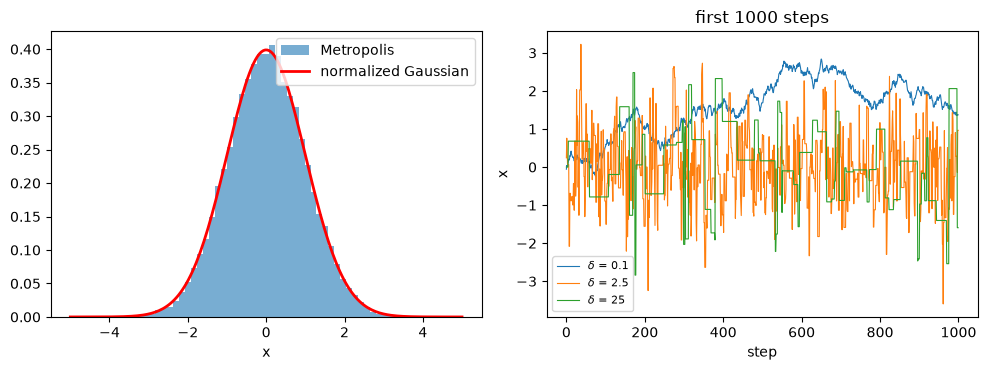

In [17]:
# CHECK — do not edit
np.random.seed(0)
samples, accept_frac = metropolis(delta)
kept = samples[burn_in:]
print("delta = %g:  mean = %.3f (expect 0)   variance = %.3f (expect %.1f)   accepted %.0f%%"
      % (delta, kept.mean(), kept.var(), sigma**2, 100*accept_frac))
assert abs(kept.mean()) < 0.05, "the mean is off; check the acceptance step"
assert abs(kept.var() - sigma**2) < 0.05, "the variance is off; are you recording x on rejection?"
assert 0.45 < accept_frac < 0.65, "acceptance should be near 56% at delta = 2.5"

runs = {}
for d in [0.1, 25.0]:
    runs[d] = metropolis(d)
    print("delta = %-4g accepted %.0f%%" % (d, 100*runs[d][1]))
assert runs[0.1][1] > 0.95 and runs[25.0][1] < 0.1, "acceptance should fall as delta grows"
print("OK")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))
grid = np.linspace(-5, 5, 200)
a1.hist(kept, bins=60, density=True, alpha=0.6, label="Metropolis")
a1.plot(grid, np.exp(-grid**2/(2*sigma**2))/(sigma*np.sqrt(2*np.pi)), "r-", lw=2, label="normalized Gaussian")
a1.set_xlabel("x"); a1.legend()
for d, s in [(0.1, runs[0.1][0]), (delta, samples), (25.0, runs[25.0][0])]:
    a2.plot(s[:1000], lw=0.8, label=r"$\delta$ = %g" % d)
a2.set_xlabel("step"); a2.set_ylabel("x"); a2.set_title("first 1000 steps"); a2.legend(fontsize=8)
plt.tight_layout();

## Problem 4 — Monte Carlo expectation values and their error bars

Estimate Gaussian moments $\langle x^k\rangle$ from samples, with error bars, and
check them against $(2n-1)!!$.

First write `mc_estimate(fx)`. Given the array of values $f(x_i)$, it returns the
estimate $\bar f$ and its error bar $\sigma_f/\sqrt N$, with
$\sigma_f^2 = \overline{f^2} - \bar f^{\,2}$. Build it from the two averages
$\bar f$ and $\overline{f^2}$, so you see each piece.

Then test whether the error bar is honest. Make $M = 1000$ independent estimates of
$\langle x^4\rangle$, each from $n = 1000$ fresh samples, and keep the estimate and
the error bar from each run. If the error bar is right, the scatter of the 1000
estimates matches the error bar a single run reports.

**Known answers.** At $N = 10^5$ the moments $k = 1, 2, 3, 4, 6$ come out at
$0, 1, 0, 3, 15$, each within a few error bars. For $k = 4$ you can work out the
error bar exactly: $\sigma_f^2 = \langle x^8\rangle - \langle x^4\rangle^2 = 105 - 9 = 96$,
so at $n = 1000$ it's $\sqrt{96}/\sqrt{1000} = 0.31$. The scatter of your 1000
estimates and the error bar of a typical run should both come out near 0.31.

The check prints how far each estimate is from the exact answer, in units of its own
error bar. A miss of more than four error bars happens by chance about once in
16,000 tries, so if you see one, look for a bug.

Last, it tries $k = -2$. The integral $\int x^{-2} e^{-x^2/2}\,dx$ diverges at
$x = 0$, so $\langle x^{-2}\rangle = \infty$, but your function still returns a
finite estimate with a finite error bar. As $N$ grows the estimate jumps around by
orders of magnitude, and the error bar, which should shrink like $1/\sqrt N$, stays
about as large as the estimate itself.

In [19]:
# GIVEN — standard normal samples and the exact moments (do not change)
rng = np.random.default_rng(1)
N = 100_000
x = rng.standard_normal(N)
exact = {1: 0, 2: 1, 3: 0, 4: 3, 6: 15}       # (2n-1)!! for even k, zero for odd k
M, n_each = 1000, 1000                          # for the honesty test

In [24]:
# FILL IN: the Monte Carlo estimate of <f> and its error bar, from the values fx = f(x_i).
def mc_estimate(fx):
    N = len(fx)
    fbar  = np.sum(fx)/N               # sample mean of f
    f2bar = np.sum(fx**2)/N               # sample mean of f^2
    sigma_f = np.sqrt(f2bar-fbar**2)             # spread of the individual values
    return fbar, sigma_f/np.sqrt(N)         # the estimate and its error bar

In [29]:
# FILL IN: M independent estimates of <x^4>, each from n_each fresh samples.
#          Keep each run's estimate and the error bar it reports.
estimates = np.zeros(M)
reported  = np.zeros(M)
for j in range(M):
    x = rng.standard_normal(n_each)
    estimate, error = mc_estimate(x**4)
    estimates[j] = estimate
    reported[j] = error

 k   estimate   error bar   exact   (estimate - exact)/error
 1     0.0033      0.0313       0    +0.11
 2     0.9787      0.0436       1    -0.49
 3     0.1470      0.1180       0    +1.25
 4     2.8545      0.3015       3    -0.48
 6    13.9528      3.2553      15    -0.32

<x^4> at n = 1000:  scatter of 1000 estimates = 0.311   typical reported error = 0.301   exact = 0.310
OK

k = -2, where the exact answer is infinite:
  N =      100   estimate =       302   error bar =       219
  N =     1000   estimate =  4.39e+06   error bar =  4.38e+06
  N =    10000   estimate =  4.44e+05   error bar =  4.39e+05
  N =   100000   estimate =  1.98e+05   error bar =  1.28e+05
  N =  1000000   estimate =  4.54e+06   error bar =  4.19e+06


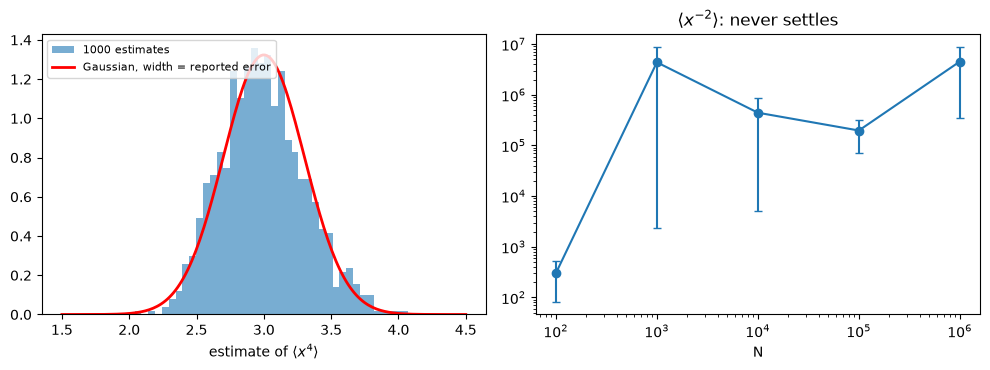

In [30]:
# CHECK — do not edit
print(" k   estimate   error bar   exact   (estimate - exact)/error")
for k, ex in exact.items():
    est, err = mc_estimate(x**k)
    print("%2d   %8.4f   %9.4f   %5d   %+6.2f" % (k, est, err, ex, (est - ex)/err))
    assert abs(est - ex) < 4*err, "<x^%d> is more than 4 error bars from exact" % k

spread, typical = estimates.std(), reported.mean()
print("\n<x^4> at n = %d:  scatter of %d estimates = %.3f   typical reported error = %.3f   exact = %.3f"
      % (n_each, M, spread, typical, np.sqrt(96/n_each)))
assert abs(estimates.mean() - 3) < 0.05, "the estimates should average to 3"
assert abs(spread/np.sqrt(96/n_each) - 1) < 0.15, "the scatter should be sqrt(96/n)"
assert abs(typical/spread - 1) < 0.15, "the reported error bar should match the actual scatter"
print("OK")

print("\nk = -2, where the exact answer is infinite:")
Ns = [10**p for p in range(2, 7)]
neg = [mc_estimate(np.random.default_rng(5).standard_normal(n)**-2.0) for n in Ns]
for n, (est, err) in zip(Ns, neg):
    print("  N = %8d   estimate = %9.3g   error bar = %9.3g" % (n, est, err))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))
a1.hist(estimates, bins=40, density=True, alpha=0.6, label="%d estimates" % M)
g = np.linspace(1.5, 4.5, 200)
a1.plot(g, np.exp(-(g-3)**2/(2*typical**2))/np.sqrt(2*np.pi*typical**2), "r-", lw=2,
        label="Gaussian, width = reported error")
a1.set_xlabel(r"estimate of $\langle x^4 \rangle$"); a1.legend(fontsize=8, loc="upper left")
a2.errorbar(Ns, [e for e, _ in neg], yerr=[s for _, s in neg], fmt="o-", capsize=3)
a2.set_xscale("log"); a2.set_yscale("log"); a2.set_xlabel("N")
a2.set_title(r"$\langle x^{-2}\rangle$: never settles")
plt.tight_layout();

## Problem 5 — Challenge: importance sampling, and choosing $p$

An ordinary integral is also an expectation value. On $[a,b]$ the uniform density is
$p = 1/(b-a)$, so

$$\int_a^b f(x)\,dx = (b-a)\,\langle f\rangle_{\rm uniform} \approx \frac{b-a}{N}\sum_{i=1}^{N} f(x_i) .$$

This is the **mean-value method**. The $\pi$ estimate was the hit-or-miss version,
with $f = 1$ inside the region and $0$ outside. In one dimension the trapezoid rule
beats it easily, but $\sigma_f/\sqrt N$ doesn't depend on dimension. $N$ grid points
in $d$ dimensions have spacing $h \sim N^{-1/d}$, so the trapezoid error goes like
$h^2 \sim N^{-2/d}$, and past $d = 4$ sampling wins. A statistical mechanics problem
has $d \sim 10^{23}$.

You can't do much about $\sqrt N$, so work on $\sigma_f$ instead. Sample from a
normalized density $p$ of your choosing:

$$I = \int f(x)\,dx = \int \frac{f(x)}{p(x)}\,p(x)\,dx \;\approx\; \frac1N \sum_{i=1}^{N} \frac{f(x_i)}{p(x_i)}, \qquad x_i \sim p .$$

This is **importance sampling**. The estimate is correct on average for any $p$
that's nonzero wherever $f$ is, and a uniform $p$ gives back the mean-value method.
The error bar is set by the spread of the ratio $f/p$, which is small when $p$ has
the shape of $f$. With $p = f/I$ exactly the spread is zero, but building that $p$
requires $I$, the number you were trying to compute. In practice you pick a $p$ that
resembles $f$ and that you know how to sample. (An older trick for the same job is
to subtract a piece you can integrate exactly, writing $f = f_1 + f_2$ with
$\int f_1$ known, and sample only $f_2$.)

Here, estimate

$$I = \int_0^\infty x^{3/2} e^{-x}\,dx = \Gamma(5/2) = \frac{3\sqrt\pi}{4} = 1.32934\ldots$$

two ways with the same number of samples, and compare the per-sample spread $\sigma$
of the values you average, since $\sigma/\sqrt N$ is the error bar.

* Uniform on $[0, L]$ with $L = 10$: average $L\,f(x)$. The cutoff drops
  $\int_{10}^\infty f\,dx \approx 0.0017$, less than half the error bar at this $N$.
* Exponential, $p_a(x) = a\,e^{-ax}$, sampled by the inverse transform from
  Problem 2: average $f(x)/p_a(x)$, for every $a$ in the sweep.

Then work out the exact spread by hand,
$\sigma^2(a) = \int_0^\infty f^2/p_a\,dx - I^2$, which is a Gamma-function integral,
and code it as `sigma_exact(a)`. The check compares it with what you measured.

**Known answers.** Every estimate lands on $1.3293$ within its error bar. Uniform
sampling gives $\sigma = 1.41$. The obvious choice $a = 1$, where $p$ decays exactly
like the integrand, is worse, with $\sigma = 2.06$, because the ratio
$f/p = x^{3/2}$ grows without bound. The minimum is at $a = 2/5$, where
$\sigma = 0.72$, half the uniform spread, so you need about a quarter as many samples
for the same error bar. Past $a = 1$ the measured $\sigma$ varies noticeably from run
to run, because the weights have heavy enough tails that even their spread is hard
to measure. At $a = 2$ the variance is infinite, the same failure as $k = -2$ in
Problem 4.

In [31]:
# GIVEN — the integrand, its exact integral, and the sweep (do not change)
def f(x):
    return x**1.5 * np.exp(-x)

I_exact  = 3*np.sqrt(np.pi)/4                       # Gamma(5/2) = 1.329340...
L        = 10.0                                     # cutoff for uniform sampling
N        = 100_000
a_values = np.round(np.arange(0.1, 1.21, 0.1), 2)
rng      = np.random.default_rng(2)

In [39]:
# FILL IN: the two kinds of weight (their mean estimates I), and the exact spread sigma(a).
def weights_uniform(N, rng):
    # L*f(x) for x uniform on [0, L]
    x = L*rng.random(N)
    return L*f(x)

def weights_exponential(a, N, rng):
    # f(x)/p_a(x) for x drawn from p_a(x) = a*exp(-a*x) by the inverse transform
    x = -np.log(1-rng.random(N))/a
    return f(x)/(a*np.exp(-a*x))

def sigma_exact(a):
    # sqrt( integral of f^2/p_a  -  I^2 ), with the integral done by hand
    return np.sqrt(6/(a*(2-a)**4)-(9*np.pi)/16)

uniform      estimate = 1.3241 +/- 0.0045   sigma = 1.409
a = 0.1      estimate = 1.3320 +/- 0.0053   sigma = 1.686   exact sigma = 1.684
a = 0.2      estimate = 1.3256 +/- 0.0033   sigma = 1.043   exact sigma = 1.044
a = 0.3      estimate = 1.3272 +/- 0.0025   sigma = 0.793   exact sigma = 0.792
a = 0.4      estimate = 1.3347 +/- 0.0023   sigma = 0.722   exact sigma = 0.722
a = 0.5      estimate = 1.3245 +/- 0.0025   sigma = 0.776   exact sigma = 0.777
a = 0.6      estimate = 1.3346 +/- 0.0029   sigma = 0.916   exact sigma = 0.914
a = 0.7      estimate = 1.3261 +/- 0.0035   sigma = 1.109   exact sigma = 1.111
a = 0.8      estimate = 1.3211 +/- 0.0043   sigma = 1.353   exact sigma = 1.360
a = 0.9      estimate = 1.3324 +/- 0.0053   sigma = 1.672   exact sigma = 1.669
a = 1.0      estimate = 1.3301 +/- 0.0065   sigma = 2.059   exact sigma = 2.057
a = 1.1      estimate = 1.3248 +/- 0.0080   sigma = 2.540   exact sigma = 2.559
a = 1.2      estimate = 1.3429 +/- 0.0100   sigma = 3.173   ex

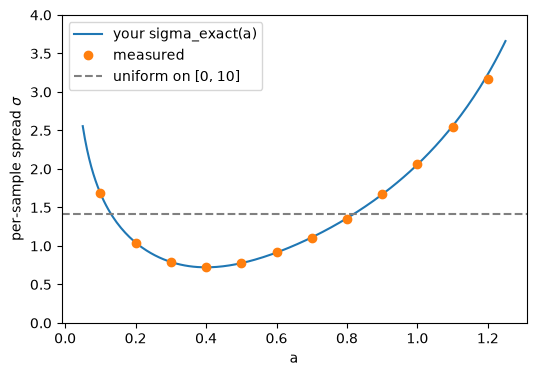

In [40]:
# CHECK — do not edit
w = weights_uniform(N, rng)
sig_u, err = w.std(), w.std()/np.sqrt(N)
print("uniform      estimate = %.4f +/- %.4f   sigma = %.3f" % (w.mean(), err, sig_u))
assert abs(w.mean() - I_exact) < 4*err, "uniform estimate is off"
assert abs(sig_u - 1.41) < 0.05, "uniform spread should be about 1.41"

sig = np.zeros(a_values.size)
for i, a in enumerate(a_values):
    w = weights_exponential(a, N, rng)
    sig[i], err = w.std(), w.std()/np.sqrt(N)
    print("a = %.1f      estimate = %.4f +/- %.4f   sigma = %.3f   exact sigma = %.3f"
          % (a, w.mean(), err, sig[i], sigma_exact(a)))
    assert abs(w.mean() - I_exact) < 4*err, "importance-sampling estimate at a = %g is off" % a

best = a_values[sig.argmin()]
print("\nsmallest spread at a = %.1f; uniform needs %.1fx the samples for the same error bar"
      % (best, (sig_u/sig.min())**2))
assert 0.3 <= best <= 0.5, "the best a should be near 2/5"
assert sig[a_values == 1.0][0] > sig_u, "a = 1 should be worse than uniform"
ok = a_values <= 1.0                                # past a = 1 the measured spread itself wobbles
assert np.allclose(sig[ok], sigma_exact(a_values[ok]), rtol=0.1), "sigma_exact disagrees with the measurement"
print("OK")

aa = np.linspace(0.05, 1.25, 200)
plt.figure(figsize=(6, 4))
plt.plot(aa, sigma_exact(aa), "-", label="your sigma_exact(a)")
plt.plot(a_values, sig, "o", label="measured")
plt.axhline(sig_u, ls="--", c="gray", label="uniform on [0, %g]" % L)
plt.ylim(0, 4); plt.xlabel("a"); plt.ylabel(r"per-sample spread $\sigma$"); plt.legend();